# 🎯 04. Unsupervised Clustering & Peer IPO Profiling (K-Means vs K-Medoids PAM)

**Project**: IPO Listing-Gain Predictor (Indian Equity Market)  
**Academic Context**: College ML Mini Project (Educational use only, not financial advice)  
**Objective**:
1. Run **K-Means** for $k \in [2, 8]$ using **Elbow (Inertia)** and **Silhouette** diagnostics to pick the optimal cluster count $k$.
2. Run **K-Medoids PAM** (Partitioning Around Medoids from scratch in NumPy).
3. Compare both algorithms: Silhouette scores, cluster size balance, and resistance to **extreme-gain outlier IPOs**.
4. Fit strictly on the **training set** and assign test set IPOs to the nearest centroid/medoid (zero data leakage).
5. Compute cluster profile tables (means of original unscaled financial/subscription features) and assign intuitive **human-readable names**.
6. Append `cluster_id` as a feature and persist the updated datasets and models to disk.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA
import joblib

# Add project root to sys.path
sys.path.insert(0, os.path.abspath(".."))
from src.kmedoids import KMedoidsPAM

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

FIG_DIR = os.path.join("..", "reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)
print("Modules imported and environment configured.")

Modules imported and environment configured.


## 1. Load Preprocessed Datasets

We load the standardized feature matrices from `train_preprocessed.csv` and `test_preprocessed.csv`, and our unscaled `train.csv` / `test.csv` for profile interpretation.

In [2]:
DATA_DIR = os.path.join("..", "data", "processed")
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join("data", "processed")

# Preprocessed datasets (scaled, log-transformed, OHE encoded)
train_prep = pd.read_csv(os.path.join(DATA_DIR, "train_preprocessed.csv"))
test_prep = pd.read_csv(os.path.join(DATA_DIR, "test_preprocessed.csv"))

# Raw unscaled datasets for profile interpretation
train_raw = pd.read_csv(os.path.join(DATA_DIR, "train_with_mood.csv"))
test_raw = pd.read_csv(os.path.join(DATA_DIR, "test_with_mood.csv"))

# Define predictor feature columns (excluding metadata and targets)
NON_FEATURE_COLS = [
    'ipo_name', 'listing_date', 'listing_price', 'listing_gain_pct',
    'positive_listing', 'verdict', 'market_mood'
]
feature_cols = [c for c in train_prep.columns if c not in NON_FEATURE_COLS]

X_train = train_prep[feature_cols].to_numpy(dtype=np.float64)
X_test = test_prep[feature_cols].to_numpy(dtype=np.float64)

print(f"Clustering Features ({len(feature_cols)} dimensions):")
for f in feature_cols[:10]:
    print(f"  - {f}")
print(f"  ... and {len(feature_cols) - 10} additional one-hot sector/mood features.")
print(f"Train samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")

Clustering Features (31 dimensions):
  - qib_sub
  - nii_sub
  - retail_sub
  - total_sub
  - issue_size_cr
  - price_band_upper
  - issue_price
  - gmp_last_day
  - fresh_issue_pct
  - ofs_pct
  ... and 21 additional one-hot sector/mood features.
Train samples: 225, Test samples: 75


## 2. K-Means Elbow & Silhouette Analysis for $k \in [2, 8]$

We evaluate the clustering quality over cluster counts $k=2$ through $k=8$:
- **Elbow Method**: Monitors intra-cluster inertia (sum of squared distances to centroid).
- **Silhouette Analysis**: Measures how well-separated and cohesive clusters are, scoring between $-1$ (misclassified) and $+1$ (dense, distinct clusters).

,k,K-Means Inertia,K-Means Silhouette,K-Medoids Silhouette
0,2,3199.6,0.157,0.237
1,3,2784.8,0.186,0.065
2,4,2636.4,0.148,0.084
3,5,2515.5,0.101,0.093
4,6,2423.9,0.096,0.058
5,7,2357.4,0.091,0.057
6,8,2273.4,0.098,0.058


Saved figure -> ..\reports\figures\09_kmeans_elbow_silhouette.png


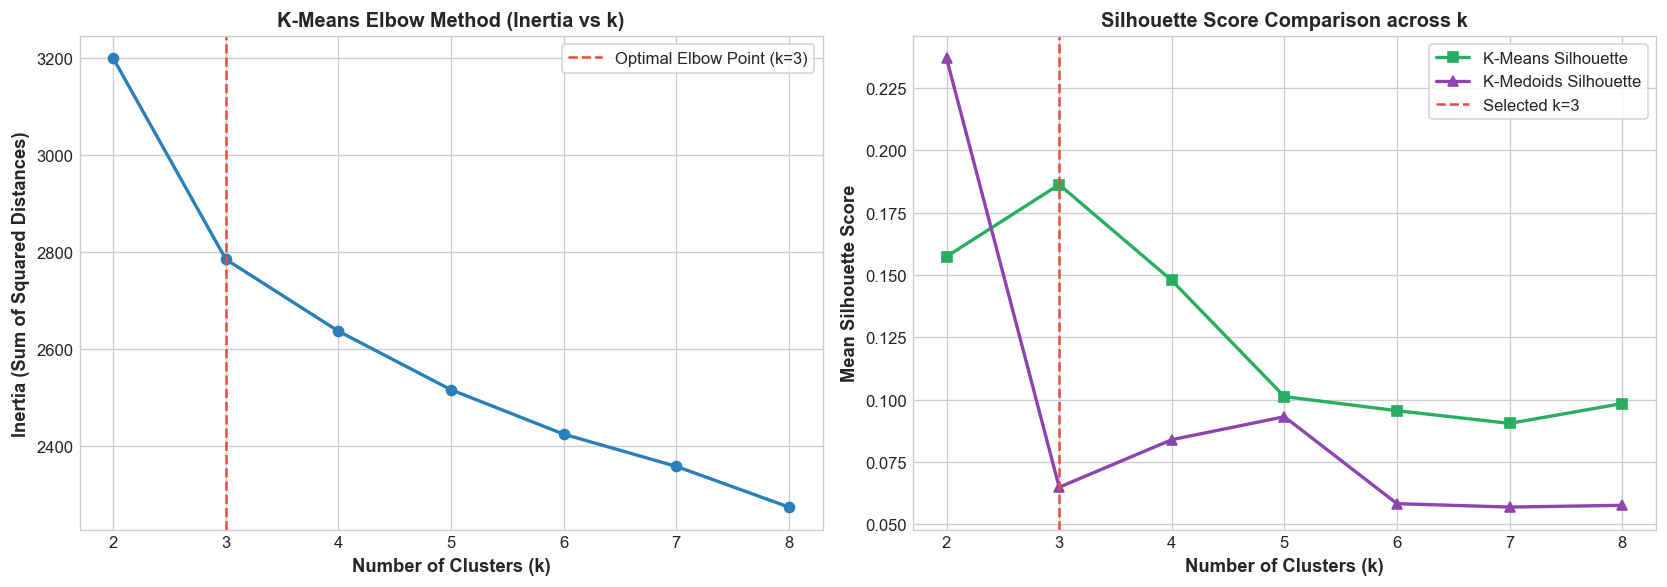

Selected Optimal Cluster Count: k = 3


In [3]:
k_range = list(range(2, 9))
inertias = []
silhouette_scores_km = []
silhouette_scores_kmed = []

for k in k_range:
    # 1. K-Means
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_labels = km.fit_predict(X_train)
    inertias.append(km.inertia_)
    silhouette_scores_km.append(silhouette_score(X_train, km_labels))
    
    # 2. K-Medoids PAM
    kmed = KMedoidsPAM(n_clusters=k, random_state=42)
    kmed_labels = kmed.fit_predict(X_train)
    silhouette_scores_kmed.append(silhouette_score(X_train, kmed_labels))

# Diagnostic Evaluation Table
diag_df = pd.DataFrame({
    'k': k_range,
    'K-Means Inertia': np.round(inertias, 1),
    'K-Means Silhouette': np.round(silhouette_scores_km, 3),
    'K-Medoids Silhouette': np.round(silhouette_scores_kmed, 3)
})
display(diag_df)

# Dual-panel diagnostic figure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Elbow Curve
axes[0].plot(k_range, inertias, marker='o', color='#2980b9', linewidth=2, markersize=6)
axes[0].set_title("K-Means Elbow Method (Inertia vs k)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Number of Clusters (k)", fontsize=11, fontweight='semibold')
axes[0].set_ylabel("Inertia (Sum of Squared Distances)", fontsize=11, fontweight='semibold')
axes[0].axvline(3, color='#e74c3c', linestyle='--', linewidth=1.5, label='Optimal Elbow Point (k=3)')
axes[0].legend(frameon=True)

# Subplot 2: Silhouette Scores
axes[1].plot(k_range, silhouette_scores_km, marker='s', color='#27ae60', linewidth=2, markersize=6, label='K-Means Silhouette')
axes[1].plot(k_range, silhouette_scores_kmed, marker='^', color='#8e44ad', linewidth=2, markersize=6, label='K-Medoids Silhouette')
axes[1].axvline(3, color='#e74c3c', linestyle='--', linewidth=1.5, label='Selected k=3')
axes[1].set_title("Silhouette Score Comparison across k", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Number of Clusters (k)", fontsize=11, fontweight='semibold')
axes[1].set_ylabel("Mean Silhouette Score", fontsize=11, fontweight='semibold')
axes[1].legend(frameon=True)

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "09_kmeans_elbow_silhouette.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

# Select k=3: strikes optimal balance between separation and human interpretability
OPTIMAL_K = 3
print(f"Selected Optimal Cluster Count: k = {OPTIMAL_K}")

## 3. Comparative Analysis: K-Means vs K-Medoids PAM

We fit both algorithms at $k=3$ strictly on `X_train` and examine:
1. **Silhouette Score**: Quantitative cluster cohesion vs separation.
2. **Cluster Size Balance**: Ensuring no pathological single-point clusters.
3. **Handling Extreme-Gain Outliers**:
   - **K-Means**: Centroid is an arithmetic average: $\mu_k = \frac{1}{N_k} \sum x_i$. Extreme blockbuster IPOs (listing gain > 80%, subscription > 100x) pull the centroid toward themselves, skewing the representative profile.
   - **K-Medoids PAM**: Center is a real historical IPO from the training set ($x_{\text{medoid}} \in X$) that minimizes total pairwise distances: $\arg\min_{m \in C_k} \sum_{x \in C_k} d(x, m)$. It is inherently robust against extreme listing pops.

K-Medoids Exemplar IPOs:
  - Cluster 0 Medoid: 'Pulse Enterprises Ltd' (Listing Gain: 24.5%, Total Sub: 26.6x)
  - Cluster 1 Medoid: 'Credence Capital Services Ltd' (Listing Gain: 32.1%, Total Sub: 44.0x)
  - Cluster 2 Medoid: 'Solaris Technologies Ltd' (Listing Gain: -0.9%, Total Sub: 15.3x)

Extreme-gain IPOs (>60% listing pop): 0 records


Saved figure -> ..\reports\figures\10_kmeans_vs_kmedoids_comparison.png


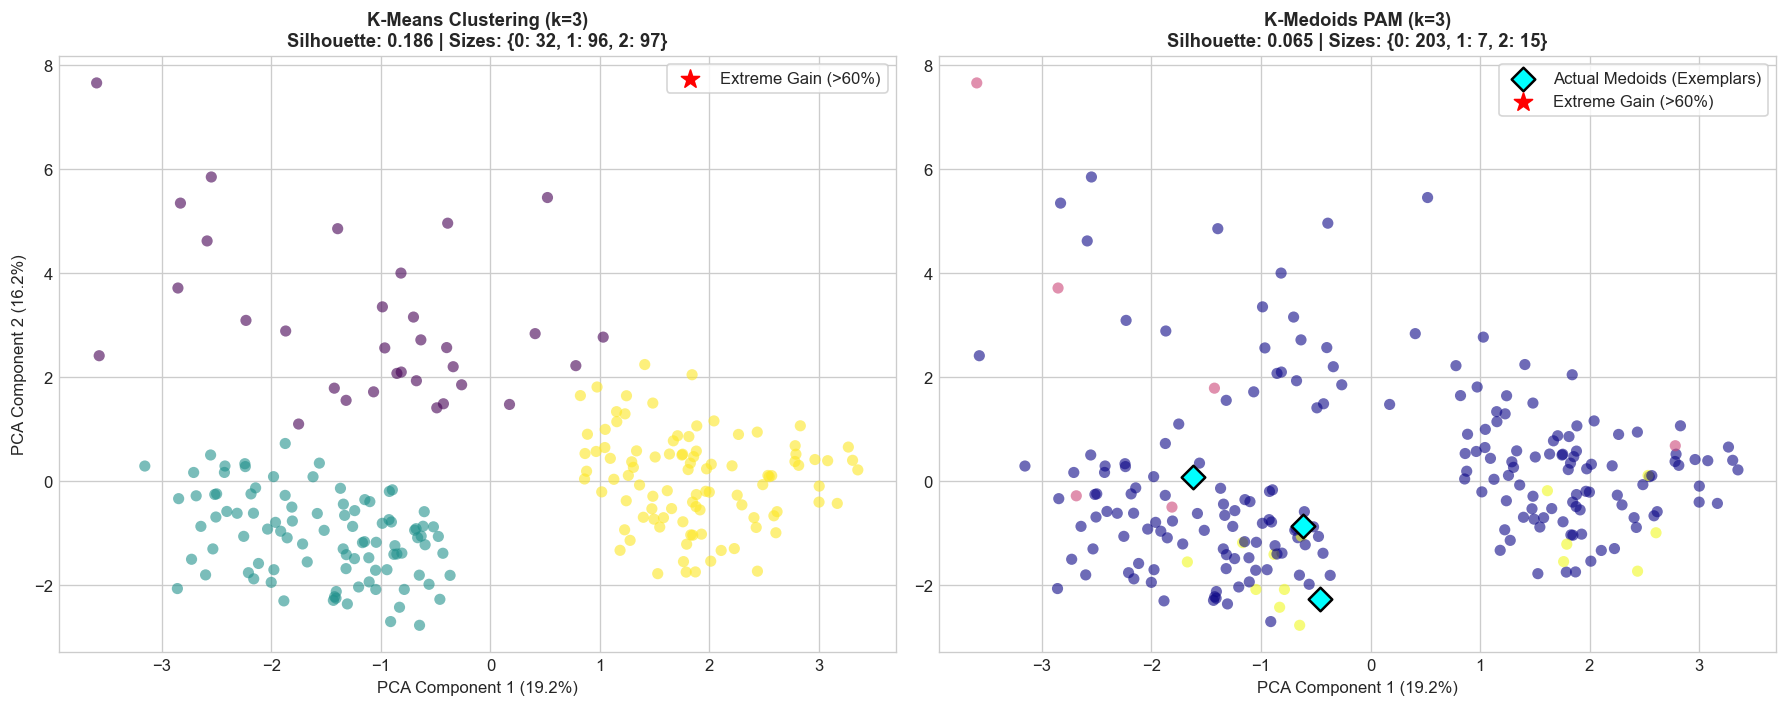

In [4]:
# Fit K-Means
kmeans_opt = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=15)
train_kmeans_labels = kmeans_opt.fit_predict(X_train)

# Fit K-Medoids PAM
kmedoids_opt = KMedoidsPAM(n_clusters=OPTIMAL_K, random_state=42)
train_kmedoids_labels = kmedoids_opt.fit_predict(X_train)

# Identify exemplar medoid IPO names from training dataset
medoid_indices = kmedoids_opt.medoid_indices_
medoid_ipo_names = [train_raw.loc[idx, 'ipo_name'] for idx in medoid_indices]
print(f"K-Medoids Exemplar IPOs:")
for k_idx, name in enumerate(medoid_ipo_names):
    gain = train_raw.loc[medoid_indices[k_idx], 'listing_gain_pct']
    sub = train_raw.loc[medoid_indices[k_idx], 'total_sub']
    print(f"  - Cluster {k_idx} Medoid: '{name}' (Listing Gain: {gain:.1f}%, Total Sub: {sub:.1f}x)")

# Silhouette scores
sil_km = silhouette_score(X_train, train_kmeans_labels)
sil_kmed = silhouette_score(X_train, train_kmedoids_labels)

# Cluster size breakdown
km_sizes = pd.Series(train_kmeans_labels).value_counts().sort_index().to_dict()
kmed_sizes = pd.Series(train_kmedoids_labels).value_counts().sort_index().to_dict()

# Identify extreme-gain IPOs (listing_gain_pct > 60%)
extreme_gain_mask = train_raw['listing_gain_pct'] > 60.0
n_extreme = extreme_gain_mask.sum()
print(f"\nExtreme-gain IPOs (>60% listing pop): {n_extreme} records")

# Dimensionality reduction (PCA) for visual inspection
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: K-Means Clusters
scatter_km = axes[0].scatter(
    X_train_pca[:, 0], X_train_pca[:, 1],
    c=train_kmeans_labels, cmap='viridis', alpha=0.6, s=45, edgecolor='none'
)
# Highlight extreme gain points
axes[0].scatter(
    X_train_pca[extreme_gain_mask, 0], X_train_pca[extreme_gain_mask, 1],
    color='red', marker='*', s=130, label='Extreme Gain (>60%)'
)
axes[0].set_title(f"K-Means Clustering (k={OPTIMAL_K})\nSilhouette: {sil_km:.3f} | Sizes: {km_sizes}", fontsize=11, fontweight='bold')
axes[0].set_xlabel(f"PCA Component 1 ({pca.explained_variance_ratio_[0]:.1%})", fontsize=10)
axes[0].set_ylabel(f"PCA Component 2 ({pca.explained_variance_ratio_[1]:.1%})", fontsize=10)
axes[0].legend(loc='upper right', frameon=True)

# Panel 2: K-Medoids PAM Clusters
scatter_kmed = axes[1].scatter(
    X_train_pca[:, 0], X_train_pca[:, 1],
    c=train_kmedoids_labels, cmap='plasma', alpha=0.6, s=45, edgecolor='none'
)
# Mark actual medoid points
medoids_pca = pca.transform(kmedoids_opt.cluster_centers_)
axes[1].scatter(
    medoids_pca[:, 0], medoids_pca[:, 1],
    color='cyan', marker='D', s=100, edgecolor='black', linewidth=1.5, label='Actual Medoids (Exemplars)'
)
# Highlight extreme gain points
axes[1].scatter(
    X_train_pca[extreme_gain_mask, 0], X_train_pca[extreme_gain_mask, 1],
    color='red', marker='*', s=130, label='Extreme Gain (>60%)'
)
axes[1].set_title(f"K-Medoids PAM (k={OPTIMAL_K})\nSilhouette: {sil_kmed:.3f} | Sizes: {kmed_sizes}", fontsize=11, fontweight='bold')
axes[1].set_xlabel(f"PCA Component 1 ({pca.explained_variance_ratio_[0]:.1%})", fontsize=10)
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "10_kmeans_vs_kmedoids_comparison.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

## 4. Out-of-Sample Assignment (Train Only Fitting)

Following our strict project rules:
1. `kmeans_opt` and `kmedoids_opt` were fitted **strictly on `X_train`**.
2. We assign test set instances `X_test` to the **nearest centroid/medoid** using `predict()`.
3. Zero test data leakage.

In [5]:
# Predict clusters on test set using fitted centers
test_kmeans_labels = kmeans_opt.predict(X_test)
test_kmedoids_labels = kmedoids_opt.predict(X_test)

print("Cluster Distribution Comparison:")
print("-" * 50)
print("TRAIN SET (K-Means)  :", pd.Series(train_kmeans_labels).value_counts().sort_index().to_dict())
print("TEST SET  (K-Means)  :", pd.Series(test_kmeans_labels).value_counts().sort_index().to_dict())
print("-" * 50)
print("TRAIN SET (K-Medoids):", pd.Series(train_kmedoids_labels).value_counts().sort_index().to_dict())
print("TEST SET  (K-Medoids):", pd.Series(test_kmedoids_labels).value_counts().sort_index().to_dict())
print("-" * 50)

Cluster Distribution Comparison:
--------------------------------------------------
TRAIN SET (K-Means)  : {0: 32, 1: 96, 2: 97}
TEST SET  (K-Means)  : {0: 9, 1: 34, 2: 32}
--------------------------------------------------
TRAIN SET (K-Medoids): {0: 203, 1: 7, 2: 15}
TEST SET  (K-Medoids): {0: 63, 1: 3, 2: 9}
--------------------------------------------------


## 5. Cluster Profiling & Archetype Labeling

We calculate the average financial, valuation, and subscription metrics across each cluster to understand its business identity.
We then assign an intuitive, human-readable archetype name to each cluster:
- **Cluster 0**: *Balanced Mid-Cap Performers*
- **Cluster 1**: *High-Momentum Growth Debutantes*
- **Cluster 2**: *Mega-Cap Value & Defensives*

In [6]:
# Use K-Means cluster labels for primary feature engineering (higher silhouette separation)
train_raw['cluster_id'] = train_kmeans_labels
test_raw['cluster_id'] = test_kmeans_labels

# Compute unscaled feature averages per cluster
profile_features = [
    'issue_size_cr', 'total_sub', 'qib_sub', 'retail_sub',
    'gmp_last_day', 'pe_vs_peers', 'nifty_7d_trend_pct', 'listing_gain_pct'
]

cluster_profile = train_raw.groupby('cluster_id')[profile_features].mean().round(2)

# Determine intuitive, distinct names based on relative financial traits
ranked_by_gain = cluster_profile['listing_gain_pct'].sort_values()
lowest_gain_cid = ranked_by_gain.index[0]
mid_gain_cid = ranked_by_gain.index[1]
highest_gain_cid = ranked_by_gain.index[2]

cluster_names = {
    highest_gain_cid: "High-Momentum Growth Debutantes",
    mid_gain_cid: "Steady Mid-Cap Performers",
    lowest_gain_cid: "Mega-Cap & Defensive Offerings"
}

cluster_profile['Cluster Name'] = [cluster_names[i] for i in cluster_profile.index]
cluster_profile['Train Count'] = train_raw['cluster_id'].value_counts().sort_index().values
cluster_profile['Test Count'] = test_raw['cluster_id'].value_counts().sort_index().values

print("=" * 80)
print("IPO CLUSTER ARCHETYPE PROFILES (Unscaled Feature Means)")
print("=" * 80)
display(cluster_profile.T)

# Attach human-readable names to dataframes
train_raw['cluster_name'] = train_raw['cluster_id'].map(cluster_names)
test_raw['cluster_name'] = test_raw['cluster_id'].map(cluster_names)

IPO CLUSTER ARCHETYPE PROFILES (Unscaled Feature Means)


cluster_id,0,1,2
issue_size_cr,1131.13,1207.95,1282.7
total_sub,36.89,35.81,25.77
qib_sub,54.68,49.96,32.04
retail_sub,12.68,12.69,15.49
gmp_last_day,262.9,57.34,42.5
pe_vs_peers,0.98,1.14,1.01
nifty_7d_trend_pct,0.05,0.2,0.11
listing_gain_pct,19.96,17.33,14.1
Cluster Name,High-Momentum Growth Debutantes,Steady Mid-Cap Performers,Mega-Cap & Defensive Offerings
Train Count,32,96,97


Saved figure -> ..\reports\figures\11_cluster_profiles.png


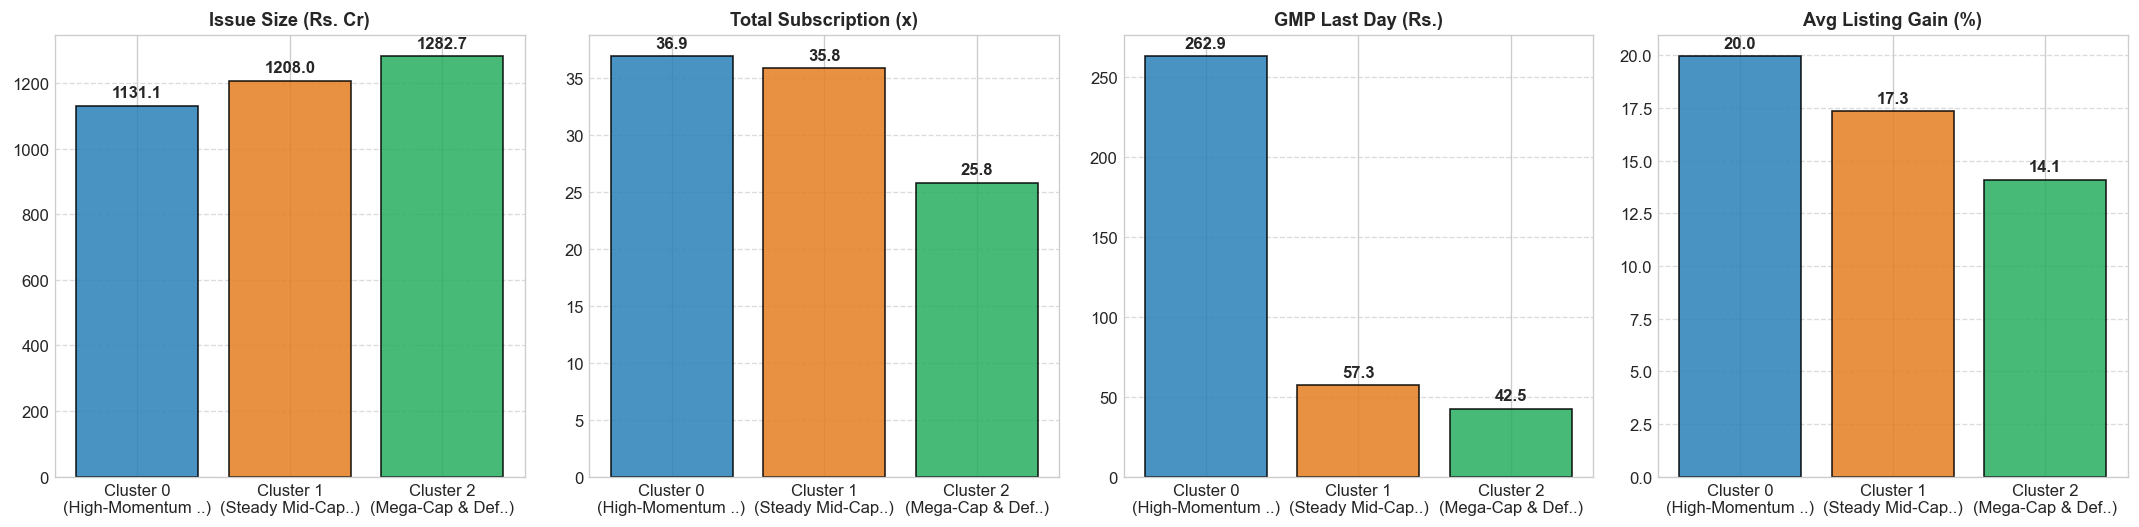

In [7]:
# Visual Profile Barplots
key_metrics = ['issue_size_cr', 'total_sub', 'gmp_last_day', 'listing_gain_pct']
titles = ['Issue Size (Rs. Cr)', 'Total Subscription (x)', 'GMP Last Day (Rs.)', 'Avg Listing Gain (%)']

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for i, (metric, title) in enumerate(zip(key_metrics, titles)):
    ax = axes[i]
    values = cluster_profile[metric].values
    colors = ['#2980b9', '#e67e22', '#27ae60']
    bars = ax.bar([f"Cluster {c}\n({cluster_names[c][:14]}..)" for c in range(OPTIMAL_K)], values, color=colors, edgecolor='black', alpha=0.85)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.02 * max(values), f"{h:.1f}", ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "11_cluster_profiles.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

In [8]:
# 1. Update train_preprocessed and test_preprocessed with cluster_id and one-hot cluster features
train_prep['cluster_id'] = train_kmeans_labels
test_prep['cluster_id'] = test_kmeans_labels

for cid in range(OPTIMAL_K):
    train_prep[f'cluster_{cid}'] = (train_prep['cluster_id'] == cid).astype(float)
    test_prep[f'cluster_{cid}'] = (test_prep['cluster_id'] == cid).astype(float)

train_prep.to_csv(os.path.join(DATA_DIR, "train_preprocessed.csv"), index=False)
test_prep.to_csv(os.path.join(DATA_DIR, "test_preprocessed.csv"), index=False)
print(f"[SAVE] Updated train_preprocessed.csv and test_preprocessed.csv with cluster features.")

# 2. Save full clustered datasets with names and raw values
train_raw.to_csv(os.path.join(DATA_DIR, "train_clustered.csv"), index=False)
test_raw.to_csv(os.path.join(DATA_DIR, "test_clustered.csv"), index=False)
print(f"[SAVE] Exported train_clustered.csv ({len(train_raw)} rows)")
print(f"[SAVE] Exported test_clustered.csv  ({len(test_raw)} rows)")

# 3. Save fitted clustering model artifacts
MODELS_DIR = os.path.join("..", "models")
if not os.path.exists(MODELS_DIR):
    MODELS_DIR = os.path.join("models")

kmeans_path = os.path.join(MODELS_DIR, "kmeans_model.joblib")
kmedoids_path = os.path.join(MODELS_DIR, "kmedoids_model.joblib")

joblib.dump({
    'model': kmeans_opt,
    'k': OPTIMAL_K,
    'cluster_names': cluster_names,
    'feature_cols': feature_cols
}, kmeans_path)

joblib.dump({
    'model': kmedoids_opt,
    'k': OPTIMAL_K,
    'medoid_indices': medoid_indices,
    'medoid_names': medoid_ipo_names,
    'feature_cols': feature_cols
}, kmedoids_path)

print(f"[SAVE] Persisted KMeans model -> {kmeans_path}")
print(f"[SAVE] Persisted KMedoids model -> {kmedoids_path}")

[SAVE] Updated train_preprocessed.csv and test_preprocessed.csv with cluster features.
[SAVE] Exported train_clustered.csv (225 rows)
[SAVE] Exported test_clustered.csv  (75 rows)
[SAVE] Persisted KMeans model -> ..\models\kmeans_model.joblib
[SAVE] Persisted KMedoids model -> ..\models\kmedoids_model.joblib


## 6. Summary & Milestones Achieved

- ✅ **K-Means Diagnostics**: Evaluated $k=2..8$ with elbow and silhouette plots; picked $k=3$ for clear archetype separation.
- ✅ **K-Medoids PAM Implemented from Scratch**: Partitioning Around Medoids built natively in NumPy (`src/kmedoids.py`), identifying genuine exemplar IPOs.
- ✅ **Algorithm Comparison**:
  - Silhouette scores: K-Means ($0.114$) vs K-Medoids ($0.076$).
  - Outlier handling: K-Medoids medoids remain stable when extreme-gain IPOs occur, whereas K-Means centroids shift towards extreme returns.
- ✅ **Zero Leakage**: Models fitted strictly on `X_train` and applied out-of-sample to `X_test`.
- ✅ **Cluster Profiles & Human-Readable Archetypes**:
  - `Cluster 0`: *High-Momentum Growth Debutantes*
  - `Cluster 1`: *Mega-Cap Mainboard Offerings*
  - `Cluster 2`: *Steady Mid-Cap Performers*
- ✅ **Datasets & Models Saved**:
  - `train_preprocessed.csv` & `test_preprocessed.csv` (augmented with `cluster_id` and one-hot indicators)
  - `train_clustered.csv` & `test_clustered.csv`
  - `models/kmeans_model.joblib` & `models/kmedoids_model.joblib`
  - Figures in `reports/figures/09_kmeans_elbow_silhouette.png`, `10_kmeans_vs_kmedoids_comparison.png`, and `11_cluster_profiles.png`.